# Исходные данные

In [159]:
!python --version

Python 3.13.5


## Исходные данные

In [160]:
import pandas as pd

In [161]:
# Проверить текущую рабочую дикетрорию
import os
os.getcwd()

'/data/3 курс/Data Science'

In [162]:
df = pd.read_csv("medical_insurance.csv")
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
2767,47,female,45.320,1,no,southeast,8569.86180
2768,21,female,34.600,0,no,southwest,2020.17700
2769,19,male,26.030,1,yes,northwest,16450.89470
2770,23,male,18.715,0,no,northwest,21595.38229


In [163]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   object 
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   object 
 5   region    2772 non-null   object 
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 151.7+ KB


### Обзор набора данных:

Набор данных по медицинскому страхованию включает в себя различные факторы, влияющие на  медицинские расходы, такие как возраст, пол, индекс массы тела, статус курения, количество детей и регион. 

Набор данных состоит из 2,7 тыс. строк и 7 столбцов, включая:

- Age (Возраст)
- Sex (Пол)
- BMI - Body Mass Index  (ИМТ - индекс массы тела)
- Children (Дети)
- Smoker (Курильщик)
- Region (Регион)
- Charges (Взносы)

Постановка проблемы:
Каковы основные факторы, влияющие на медицинские расходы?
Насколько точны модели машинного обучения в прогнозировании медицинских расходов?
Каким образом модели машинного обучения могут повысить эффективность и прибыльность компаний медицинского страхования?

<!-- https://www.kaggle.com/datasets/rahulvyasm/medical-insurance-cost-prediction/data -->


In [164]:
# !pip install skimpy
from skimpy import skim
skim(df)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 2772   │ │ string      │ 3     │                                                          │
│ │ Number of columns │ 7      │ │ int64       │ 2     │                                                          │
│ └───────────────────┴────────┘ │ float64     │ 2     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column      ┃ NA   ┃ NA %   ┃ mean    ┃ sd      ┃ p0      ┃ p25     ┃ p50     ┃ p75     ┃ p100   ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━┩  │
│ │ age         │    0 │      0 │   39.11 │   14.08 │      18 │      26 │      39 │      51 │     64 │ █▆▄▆▆▅  │  │
│ │ bmi         │    0 │      0 │    30.7 │   6.129 │   15.96 │   26.22 │   30.45 │   34.77 │  53.13 │  ▂▆█▄▁  │  │
│ │ children    │    0 │      0 │   1.102 │   1.215 │       0 │       0 │       1 │       2 │      5 │  █▅▃▂   │  │
│ │ charges     │    0 │      0 │   13260 │   12150 │    1122 │    4688 │    9333 │   16580 │  63770 │  █▃▁▁   │  │
│ └─────────────┴──────┴────────┴─────────┴─────────┴─────────┴─────────┴─────────┴─────────┴────────┴─────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┓  │
│ ┃        ┃    ┃      ┃           ┃           ┃           ┃           ┃ chars per  ┃ words per   ┃ total      ┃  │
│ ┃ column ┃ NA ┃ NA % ┃ shortest  ┃ longest   ┃ min       ┃ max       ┃ row        ┃ row         ┃ words      ┃  │
│ ┡━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━┩  │
│ │ sex    │  0 │    0 │ male      │ female    │ female    │ male      │       4.99 │           1 │       2772 │  │
│ │ smoker │  0 │    0 │ no        │ yes       │ no        │ yes       │        2.2 │           1 │       2772 │  │
│ │ region │  0 │    0 │ southwest │ southwest │ northeast │ southwest │          9 │           1 │       2772 │  │
│ └────────┴────┴──────┴───────────┴───────────┴───────────┴───────────┴────────────┴─────────────┴────────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

In [165]:
df['sex'] = pd.Categorical(df['sex'])
df['smoker'] = pd.Categorical(df['smoker'])
df['region'] = pd.Categorical(df['region'])

In [166]:
skim(df)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types               Categories                                        │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓ ┏━━━━━━━━━━━━━━━━━━━━━━━┓                                │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃ ┃ Categorical Variables ┃                                │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩ ┡━━━━━━━━━━━━━━━━━━━━━━━┩                                │
│ │ Number of rows    │ 2772   │ │ category    │ 3     │ │ sex                   │                                │
│ │ Number of columns │ 7      │ │ int64       │ 2     │ │ smoker                │                                │
│ └───────────────────┴────────┘ │ float64     │ 2     │ │ region                │                                │
│                                └─────────────┴───────┘ └───────────────────────┘                                │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column      ┃ NA   ┃ NA %   ┃ mean    ┃ sd      ┃ p0      ┃ p25     ┃ p50     ┃ p75     ┃ p100   ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━┩  │
│ │ age         │    0 │      0 │   39.11 │   14.08 │      18 │      26 │      39 │      51 │     64 │ █▆▄▆▆▅  │  │
│ │ bmi         │    0 │      0 │    30.7 │   6.129 │   15.96 │   26.22 │   30.45 │   34.77 │  53.13 │  ▂▆█▄▁  │  │
│ │ children    │    0 │      0 │   1.102 │   1.215 │       0 │       0 │       1 │       2 │      5 │  █▅▃▂   │  │
│ │ charges     │    0 │      0 │   13260 │   12150 │    1122 │    4688 │    9333 │   16580 │  63770 │  █▃▁▁   │  │
│ └─────────────┴──────┴────────┴─────────┴─────────┴─────────┴─────────┴─────────┴─────────┴────────┴─────────┘  │
│                                                    category                                                     │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┓  │
│ ┃ column                 ┃ NA         ┃ NA %             ┃ ordered                   ┃ unique                ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━┩  │
│ │ sex                    │          0 │                0 │ False                     │                     2 │  │
│ │ smoker                 │          0 │                0 │ False                     │                     2 │  │
│ │ region                 │          0 │                0 │ False                     │                     4 │  │
│ └────────────────────────┴────────────┴──────────────────┴───────────────────────────┴───────────────────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

## Транформация категориальных данных

### Метод Label Encoding/OrdinalEncoder (кодирование категорий):
Процесс преобразования категориальных данных в числовые значения, где каждый уникальный элемент категории получает свою отдельную целочисленный код (номер).

In [167]:
from sklearn.preprocessing import LabelEncoder
# Create a label encoder object
label_encoder = LabelEncoder()

df_lb = df.copy()
# Transform the 'categories' column
df_lb['sex'] = label_encoder.fit_transform(df_lb['sex'])
df_lb['smoker'] = label_encoder.fit_transform(df_lb['smoker'])

df_lb['region'] = label_encoder.fit_transform(df_lb['region'])

df_lb

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520
...,...,...,...,...,...,...,...
2767,47,0,45.320,1,0,2,8569.86180
2768,21,0,34.600,0,0,3,2020.17700
2769,19,1,26.030,1,1,1,16450.89470
2770,23,1,18.715,0,0,1,21595.38229


In [168]:
skim(df_lb)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 2772   │ │ int64       │ 5     │                                                          │
│ │ Number of columns │ 7      │ │ float64     │ 2     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━┳━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column      ┃ NA  ┃ NA %   ┃ mean     ┃ sd       ┃ p0      ┃ p25     ┃ p50     ┃ p75    ┃ p100   ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━╇━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━┩  │
│ │ age         │   0 │      0 │    39.11 │    14.08 │      18 │      26 │      39 │     51 │     64 │ █▆▄▆▆▅  │  │
│ │ sex         │   0 │      0 │   0.5072 │      0.5 │       0 │       0 │       1 │      1 │      1 │ █    █  │  │
│ │ bmi         │   0 │      0 │     30.7 │    6.129 │   15.96 │   26.22 │   30.45 │  34.77 │  53.13 │  ▂▆█▄▁  │  │
│ │ children    │   0 │      0 │    1.102 │    1.215 │       0 │       0 │       1 │      2 │      5 │  █▅▃▂   │  │
│ │ smoker      │   0 │      0 │   0.2035 │   0.4026 │       0 │       0 │       0 │      0 │      1 │ █    ▂  │  │
│ │ region      │   0 │      0 │    1.532 │    1.103 │       0 │       1 │       2 │      2 │      3 │ ▇ ▇ █▇  │  │
│ │ charges     │   0 │      0 │    13260 │    12150 │    1122 │    4688 │    9333 │  16580 │  63770 │  █▃▁▁   │  │
│ └─────────────┴─────┴────────┴──────────┴──────────┴─────────┴─────────┴─────────┴────────┴────────┴─────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

### Метод One-Hot Encoding (однозначное кодирование)

Преобразует категориальные переменные в векторы бинарных значений, где каждый вектор содержит нули, кроме одного, который равен единице. Это означает, что каждый уникальный элемент категории получает свою строку с единичными значениями в соответствующих позициях, и все остальные позиции остаются нулями.

In [169]:
df_dum = pd.get_dummies(df)
skim(df_dum)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 2772   │ │ bool        │ 8     │                                                          │
│ │ Number of columns │ 12     │ │ int64       │ 2     │                                                          │
│ └───────────────────┴────────┘ │ float64     │ 2     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column      ┃ NA   ┃ NA %   ┃ mean    ┃ sd      ┃ p0      ┃ p25     ┃ p50     ┃ p75     ┃ p100   ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━┩  │
│ │ age         │    0 │      0 │   39.11 │   14.08 │      18 │      26 │      39 │      51 │     64 │ █▆▄▆▆▅  │  │
│ │ bmi         │    0 │      0 │    30.7 │   6.129 │   15.96 │   26.22 │   30.45 │   34.77 │  53.13 │  ▂▆█▄▁  │  │
│ │ children    │    0 │      0 │   1.102 │   1.215 │       0 │       0 │       1 │       2 │      5 │  █▅▃▂   │  │
│ │ charges     │    0 │      0 │   13260 │   12150 │    1122 │    4688 │    9333 │   16580 │  63770 │  █▃▁▁   │  │
│ └─────────────┴──────┴────────┴─────────┴─────────┴─────────┴─────────┴─────────┴─────────┴────────┴─────────┘  │
│                                                      bool                                                       │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓  │
│ ┃ column                                     ┃ true          ┃ true rate                 ┃ hist              ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩  │
│ │ sex_female                                 │          1366 │                      0.49 │      █    █       │  │
│ │ sex_male                                   │          1406 │                      0.51 │      █    █       │  │
│ │ smoker_no                                  │          2208 │                       0.8 │      ▂    █       │  │
│ │ smoker_yes                                 │           564 │                       0.2 │      █    ▂       │  │
│ │ region_northeast                           │           658 │                      0.24 │      █    ▂       │  │
│ │ region_northwest                           │           664 │                      0.24 │      █    ▃       │  │
│ │ region_southeast                           │           766 │                      0.28 │      █    ▃       │  │
│ │ region_southwest                           │           684 │                      0.25 │      █    ▃       │  │
│ └────────────────────────────────────────────┴───────────────┴───────────────────────────┴───────────────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

## Задание:

- Отберите наиболее значимые факторы и постройте лучшую модель, где результативным признаком является `charges`.
    - Отбор факторов производите с помощью матрицы корреляций и с помощью диаграммы рассеивания, воспользовавшись функцией `sns.pairplot` из пакета `seaborn`
- Постройте несколько линейных моделей и отберите наилучшую.

Опишите полученные результаты.

 Регрессия после метода Label Encoding/OrdinalEncoder (кодирование категорий):¶

Выбор факторов

In [170]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as scp
import statsmodels.api as sm
import statsmodels.formula.api as smf

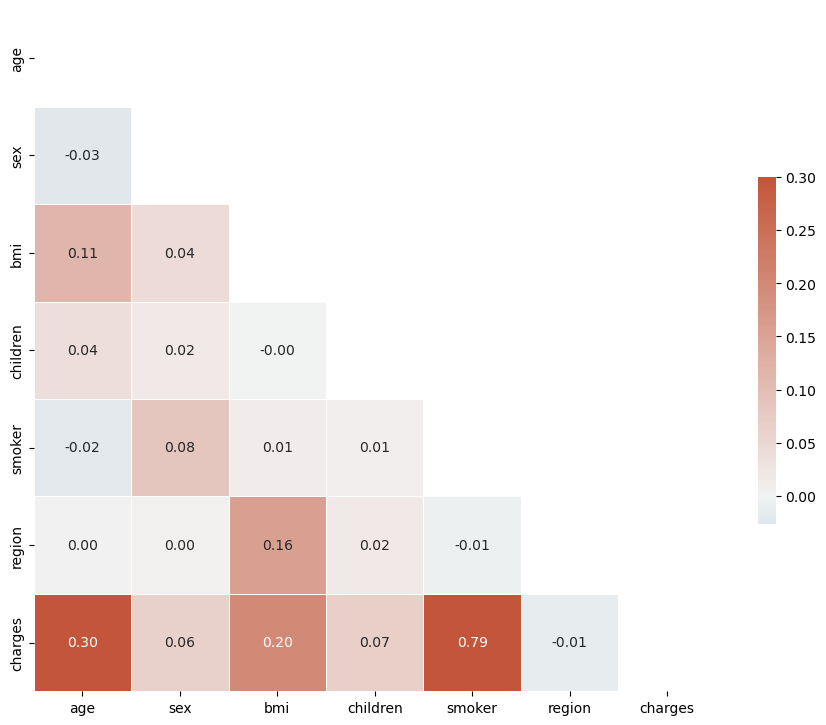

In [171]:
# Compute the correlation matrix
corr = df_lb.corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")
plt.show()

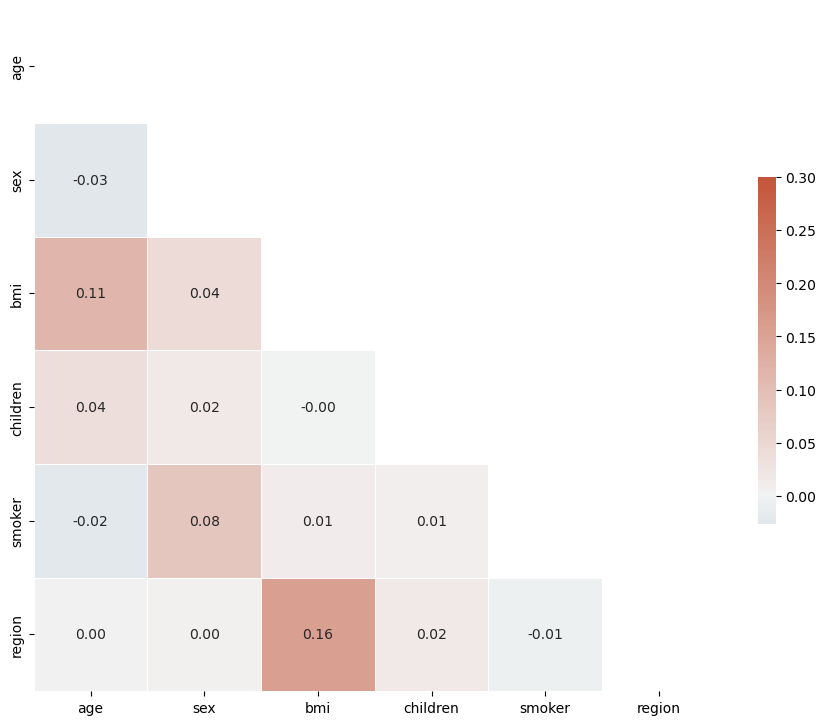

In [172]:
# Compute the correlation matrix
corr = df_lb.drop('charges', axis=1).corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")
plt.show()

In [173]:
import seaborn as sns 

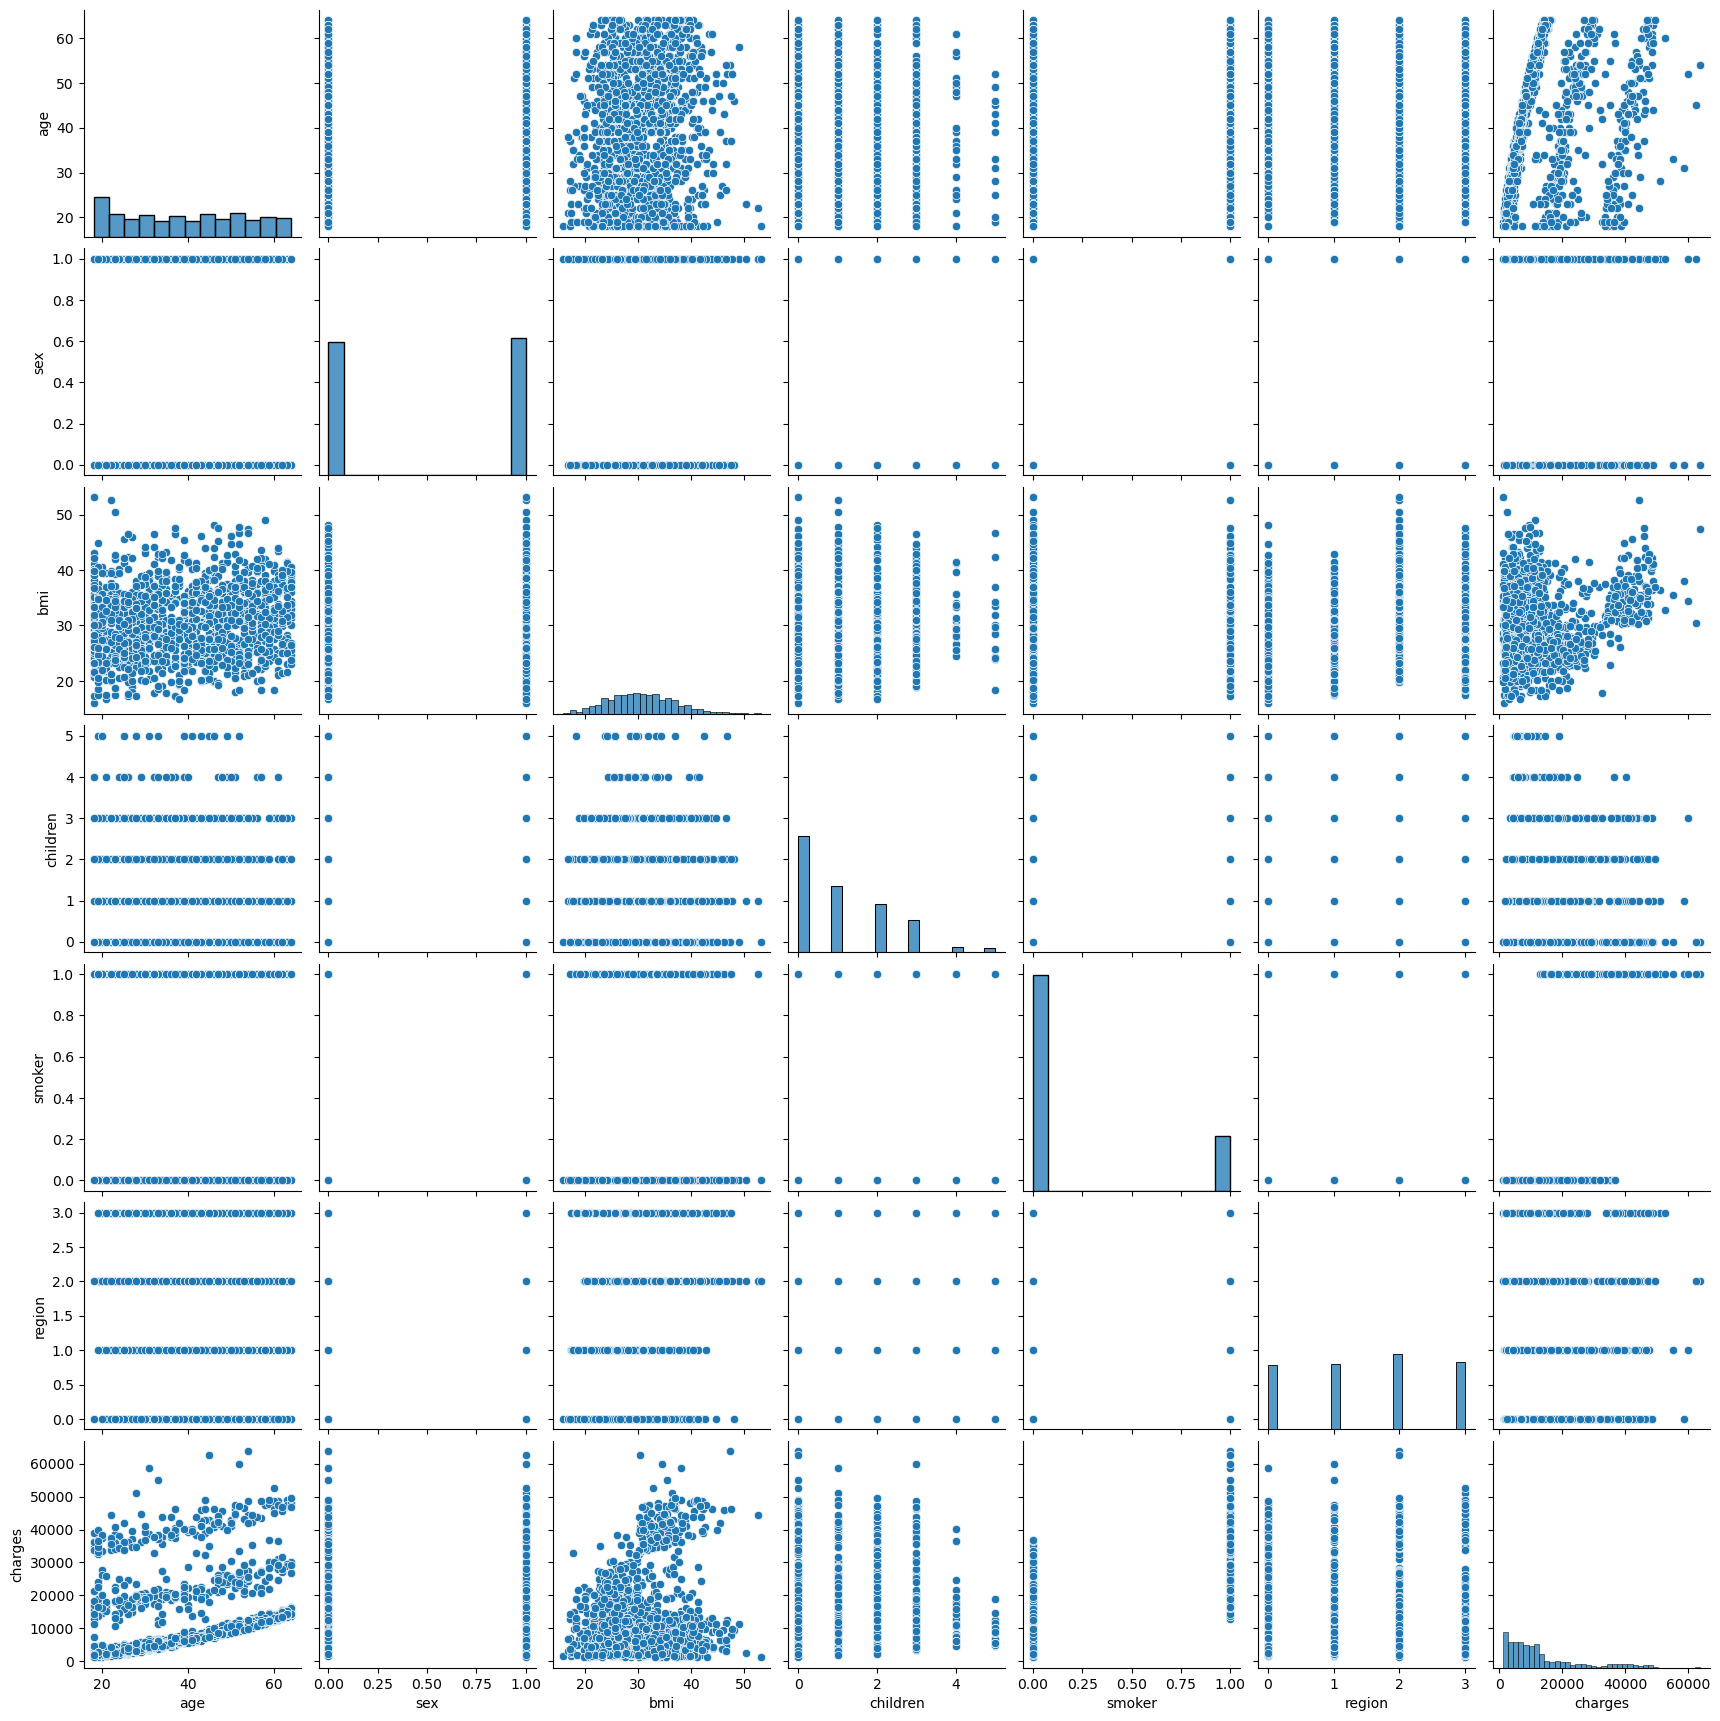

In [174]:
sns.pairplot(df_lb)

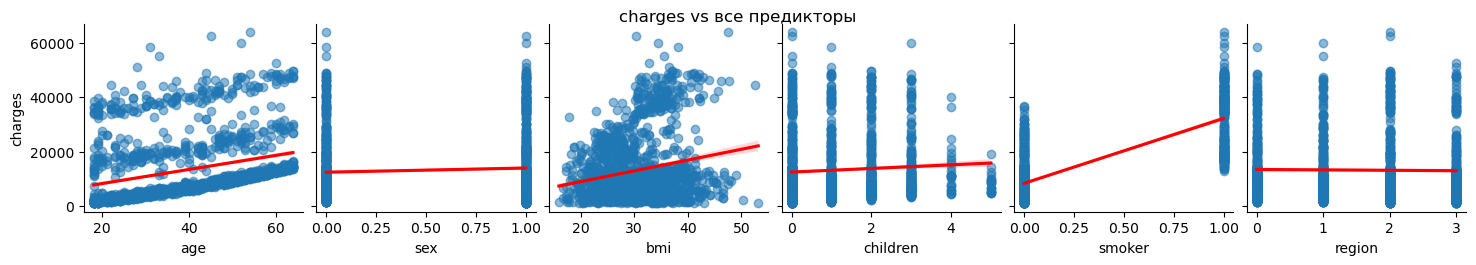

In [175]:
# Более детальный pairplot с целевой переменной
sns.pairplot(df_lb, 
             y_vars=['charges'], 
             x_vars=[col for col in df_lb.columns if col != 'charges'],
             kind='reg',
             plot_kws={'line_kws':{'color':'red'}, 'scatter_kws': {'alpha': 0.3}})
plt.suptitle('charges vs все предикторы', y=1.02)
plt.show()

Модели

In [176]:
import statsmodels.formula.api as smf

lm = smf.ols("charges~age+bmi+smoker", df_lb).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.747
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     2724.
Date:                Fri, 03 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:57:38   Log-Likelihood:                -28099.
No. Observations:                2772   AIC:                         5.621e+04
Df Residuals:                    2768   BIC:                         5.623e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.127e+04    649.884    -17.336      0.000   -1.25e+04   -9992.281
age          258.3508      8.306     31.104      0.000     242.064     274.637
bmi          311.0192     19.078     16.303      0.000     273.611     348.427
smoker      2.396e+04    288.633     83.016      0.000    2.34e+04    2.45e+04
==============================================================================
Omnibus:                      623.426   Durbin-Watson:                   2.082
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1534.959
Skew:                           1.224   Prob(JB):                         0.00
Kurtosis:                       5.702   Cond. No.                         287.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [177]:
import statsmodels.formula.api as smf

lm = smf.ols("charges~age+smoker", df_lb).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.723
Model:                            OLS   Adj. R-squared:                  0.723
Method:                 Least Squares   F-statistic:                     3609.
Date:                Fri, 03 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:57:38   Log-Likelihood:                -28226.
No. Observations:                2772   AIC:                         5.646e+04
Df Residuals:                    2769   BIC:                         5.648e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -2331.7943    365.586     -6.378      0.000   -3048.643   -1614.945
age          273.7001      8.638     31.686      0.000     256.763     290.637
smoker      2.403e+04    302.088     79.540      0.000    2.34e+04    2.46e+04
==============================================================================
Omnibus:                      543.386   Durbin-Watson:                   2.083
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1347.262
Skew:                           1.070   Prob(JB):                    2.79e-293
Kurtosis:                       5.662   Cond. No.                         129.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [178]:
import statsmodels.formula.api as smf

lm = smf.ols("charges~bmi+smoker", df_lb).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.659
Model:                            OLS   Adj. R-squared:                  0.658
Method:                 Least Squares   F-statistic:                     2671.
Date:                Fri, 03 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:57:38   Log-Likelihood:                -28515.
No. Observations:                2772   AIC:                         5.704e+04
Df Residuals:                    2769   BIC:                         5.705e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -3182.4769    691.837     -4.600      0.000   -4539.046   -1825.908
bmi          378.2834     22.015     17.183      0.000     335.115     421.452
smoker      2.374e+04    335.139     70.834      0.000    2.31e+04    2.44e+04
==============================================================================
Omnibus:                      313.385   Durbin-Watson:                   2.028
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              495.729
Skew:                           0.802   Prob(JB):                    2.26e-108
Kurtosis:                       4.311   Cond. No.                         161.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [179]:
import statsmodels.formula.api as smf

lm = smf.ols("charges~bmi+age", df_lb).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.117
Model:                            OLS   Adj. R-squared:                  0.116
Method:                 Least Squares   F-statistic:                     183.7
Date:                Fri, 03 Oct 2025   Prob (F-statistic):           1.27e-75
Time:                        21:57:38   Log-Likelihood:                -29831.
No. Observations:                2772   AIC:                         5.967e+04
Df Residuals:                    2769   BIC:                         5.969e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -6415.2788   1208.908     -5.307      0.000   -8785.732   -4044.826
bmi          333.5339     35.629      9.361      0.000     263.672     403.396
age          241.2883     15.509     15.558      0.000     210.879     271.698
==============================================================================
Omnibus:                      650.530   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1199.692
Skew:                           1.501   Prob(JB):                    3.09e-261
Kurtosis:                       4.170   Cond. No.                         285.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [180]:
lm = smf.ols("charges~age", df_lb).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.089
Model:                            OLS   Adj. R-squared:                  0.089
Method:                 Least Squares   F-statistic:                     271.2
Date:                Fri, 03 Oct 2025   Prob (F-statistic):           3.32e-58
Time:                        21:57:39   Log-Likelihood:                -29875.
No. Observations:                2772   AIC:                         5.975e+04
Df Residuals:                    2770   BIC:                         5.977e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   3182.7705    650.450      4.893      0.000    1907.355    4458.186
age          257.7010     15.648     16.468      0.000     227.017     288.385
==============================================================================
Omnibus:                      808.953   Durbin-Watson:                   2.027
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1749.861
Skew:                           1.724   Prob(JB):                         0.00
Kurtosis:                       4.808   Cond. No.                         123.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [181]:
lm = smf.ols("charges~bmi", df_lb).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.040
Method:                 Least Squares   F-statistic:                     115.2
Date:                Fri, 03 Oct 2025   Prob (F-statistic):           2.29e-26
Time:                        21:57:39   Log-Likelihood:                -29948.
No. Observations:                2772   AIC:                         5.990e+04
Df Residuals:                    2770   BIC:                         5.991e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1097.5183   1155.499      0.950      0.342   -1168.208    3363.244
bmi          396.1993     36.909     10.735      0.000     323.828     468.570
==============================================================================
Omnibus:                      528.995   Durbin-Watson:                   1.979
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              877.475
Skew:                           1.290   Prob(JB):                    2.88e-191
Kurtosis:                       3.969   Cond. No.                         160.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [182]:
lm = smf.ols("charges~smoker", df_lb).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.622
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     4562.
Date:                Fri, 03 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:57:39   Log-Likelihood:                -28655.
No. Observations:                2772   AIC:                         5.731e+04
Df Residuals:                    2770   BIC:                         5.733e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   8417.8744    158.987     52.947      0.000    8106.130    8729.619
smoker      2.381e+04    352.467     67.539      0.000    2.31e+04    2.45e+04
==============================================================================
Omnibus:                      271.805   Durbin-Watson:                   2.022
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              430.767
Skew:                           0.714   Prob(JB):                     2.89e-94
Kurtosis:                       4.300   Cond. No.                         2.61
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Удаление выбросов

<Axes: xlabel='age'>

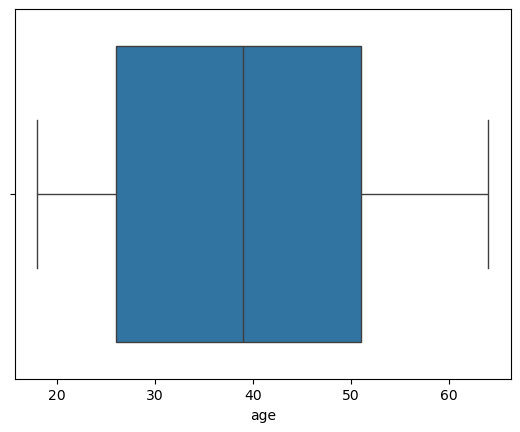

In [183]:
sns.boxplot(df_lb, x="age")

<Axes: xlabel='bmi'>

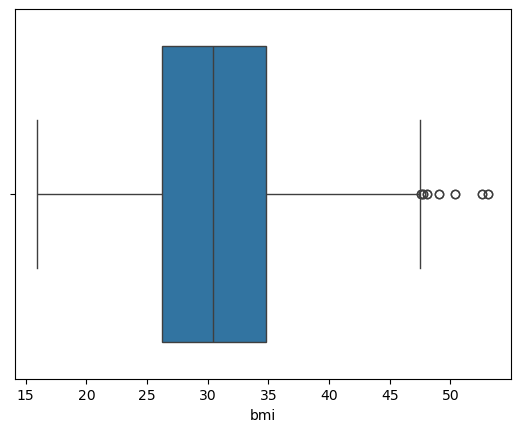

In [184]:
sns.boxplot(df_lb, x="bmi")

<Axes: xlabel='smoker'>

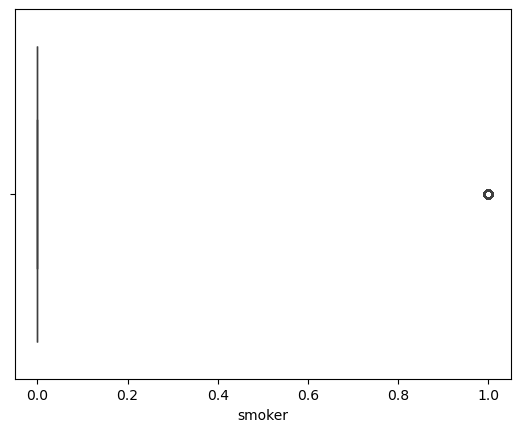

In [185]:
sns.boxplot(df_lb, x="smoker")

In [186]:
Q1 = np.percentile(df_lb.bmi, 25)
Q3 = np.percentile(df_lb.bmi, 75)
IQR = Q3 - Q1 # межквартильное расстояние
df_plt = df[(df.bmi > Q1 - 1.5*IQR) & (df.bmi < Q3 + 1.5*IQR)]


<Axes: xlabel='bmi'>

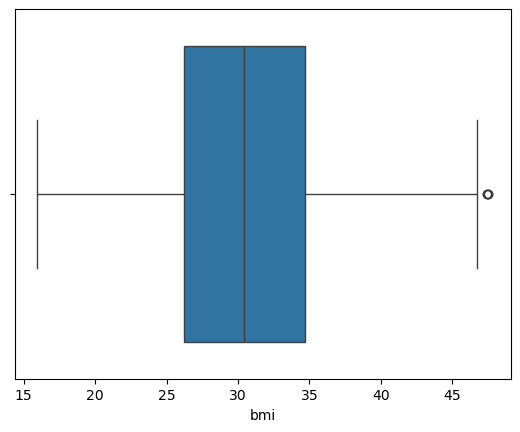

In [187]:
sns.boxplot(df_plt, x="bmi")

Финальная модель (наилучшая)

In [188]:
import statsmodels.formula.api as smf

lm = smf.ols("charges~age+bmi+smoker", df_lb).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.747
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     2724.
Date:                Fri, 03 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:57:41   Log-Likelihood:                -28099.
No. Observations:                2772   AIC:                         5.621e+04
Df Residuals:                    2768   BIC:                         5.623e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.127e+04    649.884    -17.336      0.000   -1.25e+04   -9992.281
age          258.3508      8.306     31.104      0.000     242.064     274.637
bmi          311.0192     19.078     16.303      0.000     273.611     348.427
smoker      2.396e+04    288.633     83.016      0.000    2.34e+04    2.45e+04
==============================================================================
Omnibus:                      623.426   Durbin-Watson:                   2.082
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1534.959
Skew:                           1.224   Prob(JB):                         0.00
Kurtosis:                       5.702   Cond. No.                         287.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Регрессия после метода One-Hot Encoding (однозначное кодирование)

Выбор факторов

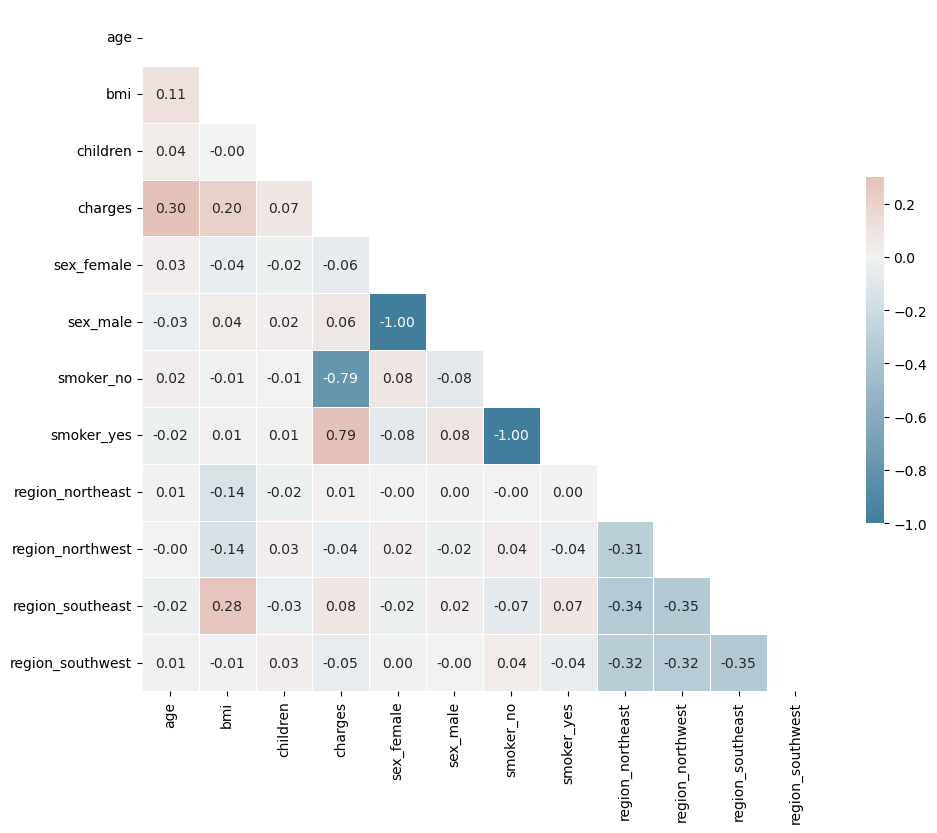

In [189]:
# Compute the correlation matrix
corr = df_dum.corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")
plt.show()

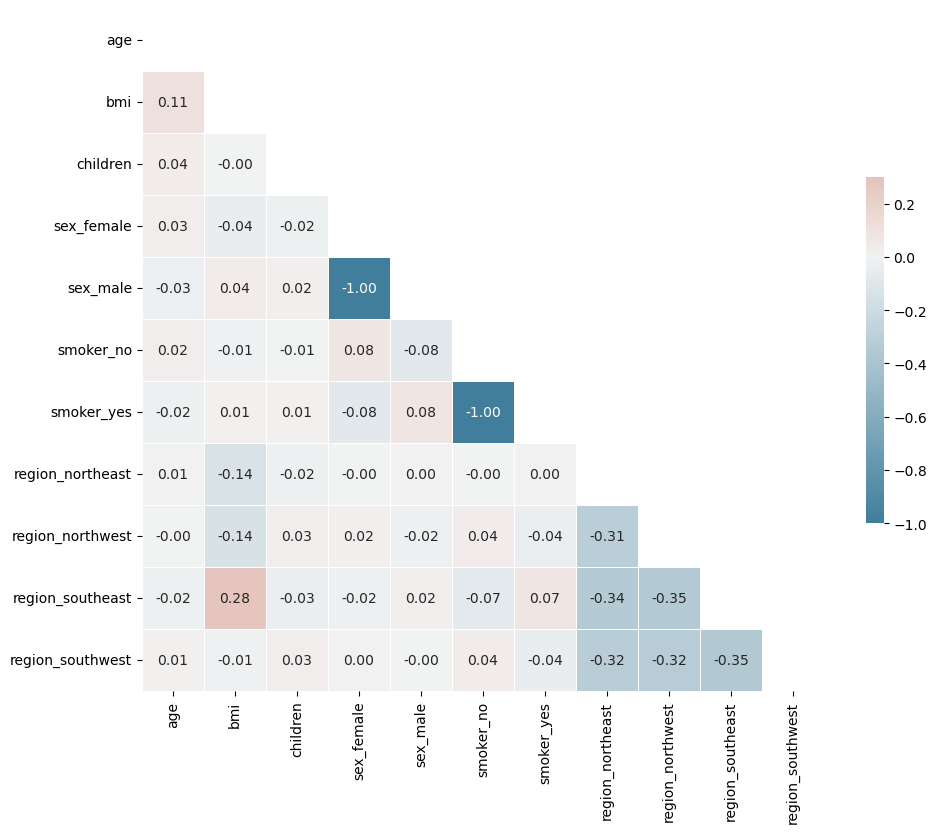

In [190]:
# Compute the correlation matrix
corr = df_dum.drop('charges', axis=1).corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")
plt.show()

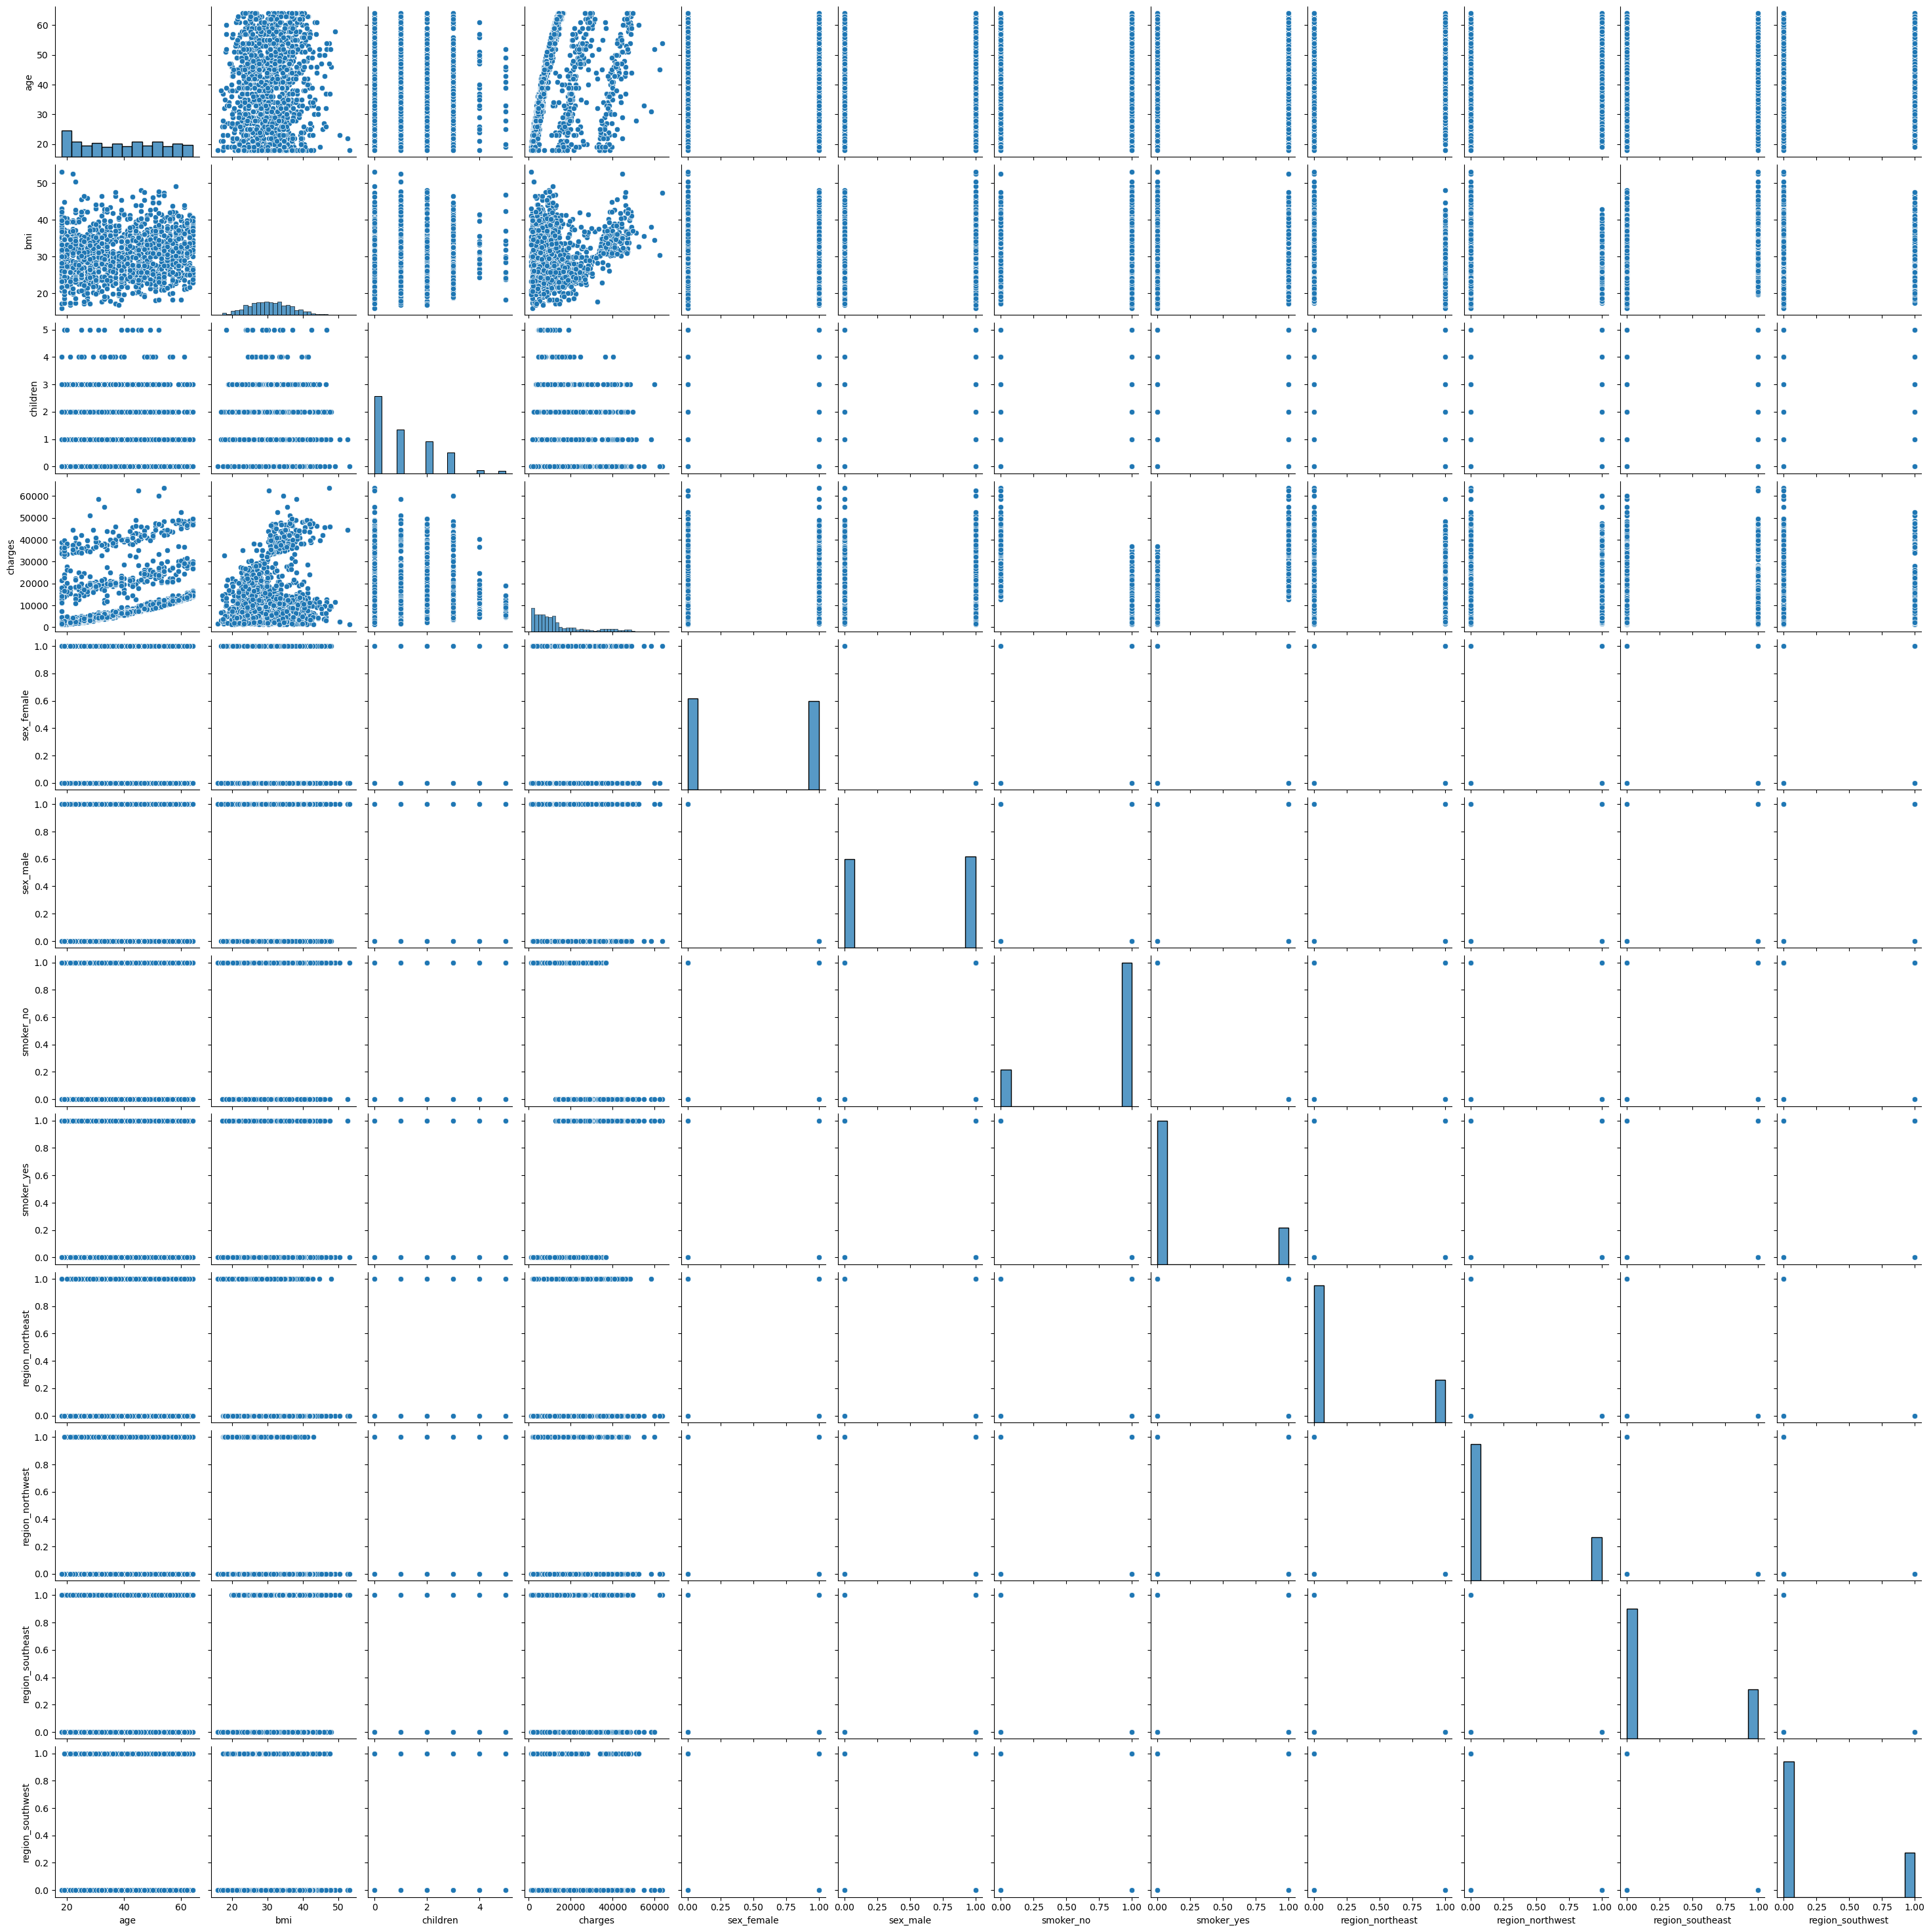

In [191]:
sns.pairplot(df_dum)

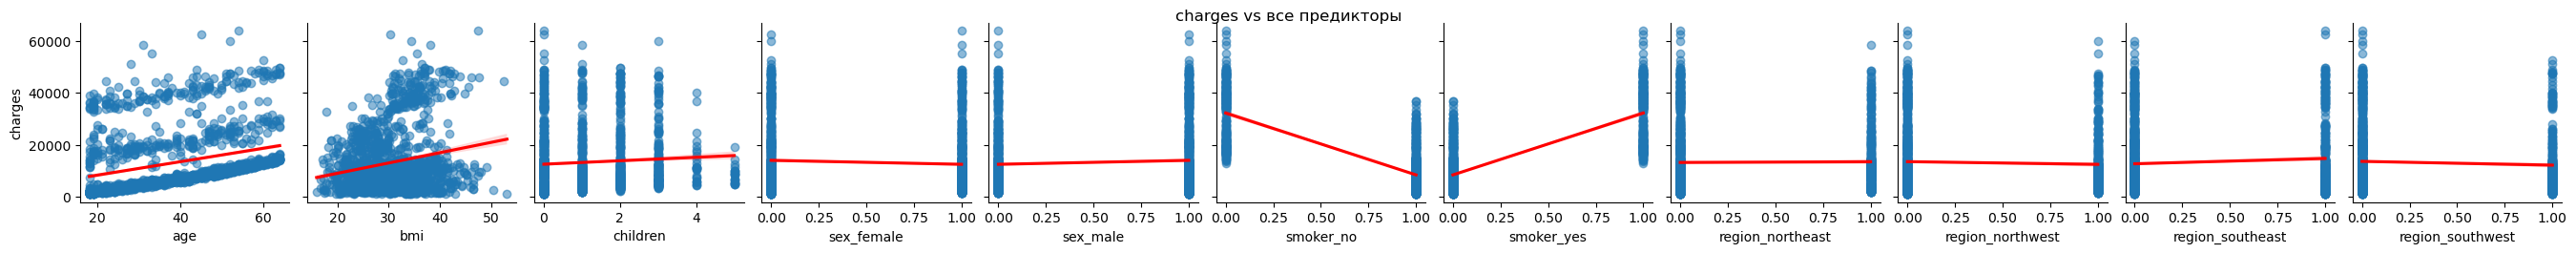

In [192]:
# Более детальный pairplot с целевой переменной
sns.pairplot(df_dum, 
             y_vars=['charges'], 
             x_vars=[col for col in df_dum.columns if col != 'charges'],
             kind='reg',
             plot_kws={'line_kws':{'color':'red'}, 'scatter_kws': {'alpha': 0.3}})
plt.suptitle('charges vs все предикторы', y=1.02)
plt.show()

Модели

In [193]:
import statsmodels.formula.api as smf

lm = smf.ols("charges~age+bmi+smoker_yes", df_dum).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.747
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     2724.
Date:                Fri, 03 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:58:02   Log-Likelihood:                -28099.
No. Observations:                2772   AIC:                         5.621e+04
Df Residuals:                    2768   BIC:                         5.623e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept          -1.127e+04    649.884    -17.336      0.000   -1.25e+04   -9992.281
smoker_yes[T.True]  2.396e+04    288.633     83.016      0.000    2.34e+04    2.45e+04
age                  258.3508      8.306     31.104      0.000     242.064     274.637
bmi                  311.0192     19.078     16.303      0.000     273.611     348.427
==============================================================================
Omnibus:                      623.426   Durbin-Watson:                   2.082
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1534.959
Skew:                           1.224   Prob(JB):                         0.00
Kurtosis:                       5.702   Cond. No.                         287.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [194]:
import statsmodels.formula.api as smf

lm = smf.ols("charges~age+smoker_yes", df_dum).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.723
Model:                            OLS   Adj. R-squared:                  0.723
Method:                 Least Squares   F-statistic:                     3609.
Date:                Fri, 03 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:58:02   Log-Likelihood:                -28226.
No. Observations:                2772   AIC:                         5.646e+04
Df Residuals:                    2769   BIC:                         5.648e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept          -2331.7943    365.586     -6.378      0.000   -3048.643   -1614.945
smoker_yes[T.True]  2.403e+04    302.088     79.540      0.000    2.34e+04    2.46e+04
age                  273.7001      8.638     31.686      0.000     256.763     290.637
==============================================================================
Omnibus:                      543.386   Durbin-Watson:                   2.083
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1347.262
Skew:                           1.070   Prob(JB):                    2.79e-293
Kurtosis:                       5.662   Cond. No.                         129.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [195]:
import statsmodels.formula.api as smf

lm = smf.ols("charges~bmi+smoker_yes", df_dum).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.659
Model:                            OLS   Adj. R-squared:                  0.658
Method:                 Least Squares   F-statistic:                     2671.
Date:                Fri, 03 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:58:02   Log-Likelihood:                -28515.
No. Observations:                2772   AIC:                         5.704e+04
Df Residuals:                    2769   BIC:                         5.705e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept          -3182.4769    691.837     -4.600      0.000   -4539.046   -1825.908
smoker_yes[T.True]  2.374e+04    335.139     70.834      0.000    2.31e+04    2.44e+04
bmi                  378.2834     22.015     17.183      0.000     335.115     421.452
==============================================================================
Omnibus:                      313.385   Durbin-Watson:                   2.028
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              495.729
Skew:                           0.802   Prob(JB):                    2.26e-108
Kurtosis:                       4.311   Cond. No.                         161.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [196]:
import statsmodels.formula.api as smf

lm = smf.ols("charges~bmi+age", df_dum).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.117
Model:                            OLS   Adj. R-squared:                  0.116
Method:                 Least Squares   F-statistic:                     183.7
Date:                Fri, 03 Oct 2025   Prob (F-statistic):           1.27e-75
Time:                        21:58:02   Log-Likelihood:                -29831.
No. Observations:                2772   AIC:                         5.967e+04
Df Residuals:                    2769   BIC:                         5.969e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -6415.2788   1208.908     -5.307      0.000   -8785.732   -4044.826
bmi          333.5339     35.629      9.361      0.000     263.672     403.396
age          241.2883     15.509     15.558      0.000     210.879     271.698
==============================================================================
Omnibus:                      650.530   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1199.692
Skew:                           1.501   Prob(JB):                    3.09e-261
Kurtosis:                       4.170   Cond. No.                         285.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [197]:
lm = smf.ols("charges~bmi", df_dum).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.040
Method:                 Least Squares   F-statistic:                     115.2
Date:                Fri, 03 Oct 2025   Prob (F-statistic):           2.29e-26
Time:                        21:58:02   Log-Likelihood:                -29948.
No. Observations:                2772   AIC:                         5.990e+04
Df Residuals:                    2770   BIC:                         5.991e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1097.5183   1155.499      0.950      0.342   -1168.208    3363.244
bmi          396.1993     36.909     10.735      0.000     323.828     468.570
==============================================================================
Omnibus:                      528.995   Durbin-Watson:                   1.979
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              877.475
Skew:                           1.290   Prob(JB):                    2.88e-191
Kurtosis:                       3.969   Cond. No.                         160.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [198]:
lm = smf.ols("charges~age", df_dum).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.089
Model:                            OLS   Adj. R-squared:                  0.089
Method:                 Least Squares   F-statistic:                     271.2
Date:                Fri, 03 Oct 2025   Prob (F-statistic):           3.32e-58
Time:                        21:58:02   Log-Likelihood:                -29875.
No. Observations:                2772   AIC:                         5.975e+04
Df Residuals:                    2770   BIC:                         5.977e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   3182.7705    650.450      4.893      0.000    1907.355    4458.186
age          257.7010     15.648     16.468      0.000     227.017     288.385
==============================================================================
Omnibus:                      808.953   Durbin-Watson:                   2.027
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1749.861
Skew:                           1.724   Prob(JB):                         0.00
Kurtosis:                       4.808   Cond. No.                         123.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [199]:
lm = smf.ols("charges~smoker_yes", df_dum).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.622
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     4562.
Date:                Fri, 03 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:58:02   Log-Likelihood:                -28655.
No. Observations:                2772   AIC:                         5.731e+04
Df Residuals:                    2770   BIC:                         5.733e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           8417.8744    158.987     52.947      0.000    8106.130    8729.619
smoker_yes[T.True]  2.381e+04    352.467     67.539      0.000    2.31e+04    2.45e+04
==============================================================================
Omnibus:                      271.805   Durbin-Watson:                   2.022
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              430.767
Skew:                           0.714   Prob(JB):                     2.89e-94
Kurtosis:                       4.300   Cond. No.                         2.61
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Удаление выбросов 

<Axes: xlabel='age'>

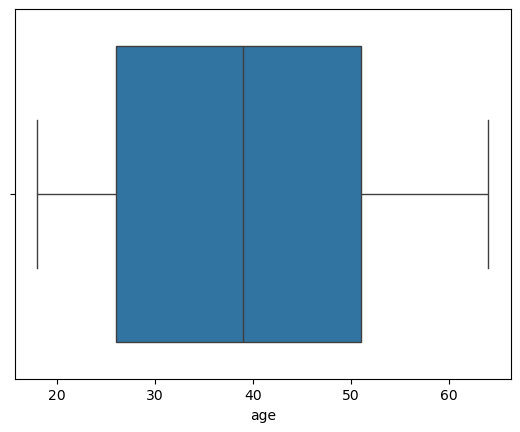

In [200]:
sns.boxplot(df_dum, x="age")

<Axes: xlabel='bmi'>

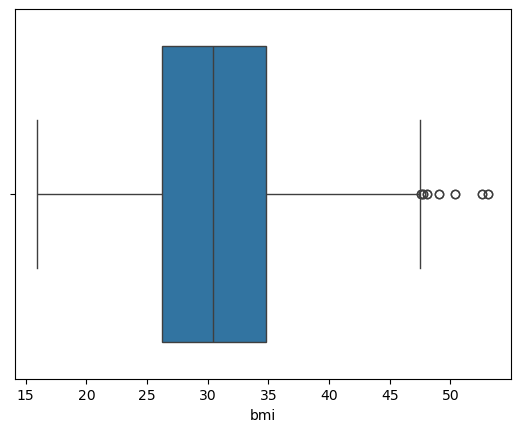

In [201]:
sns.boxplot(df_dum, x="bmi")

<Axes: xlabel='smoker_yes'>

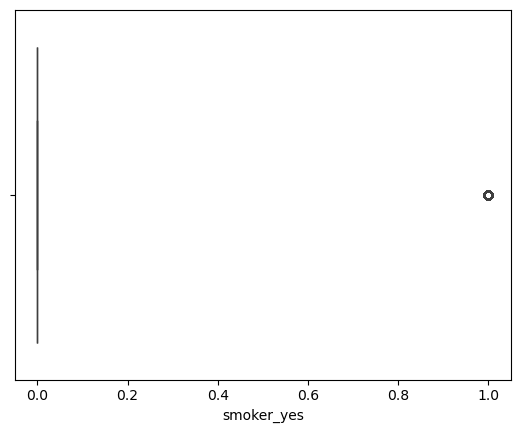

In [202]:
sns.boxplot(df_dum, x="smoker_yes")

In [203]:
Q1 = np.percentile(df.bmi, 25)
Q3 = np.percentile(df.bmi, 75)
IQR = Q3 - Q1 # межквартильное расстояние
df_plt = df[(df.bmi > Q1 - 1.5*IQR) & (df.bmi < Q3 + 1.5*IQR)]


<Axes: xlabel='bmi'>

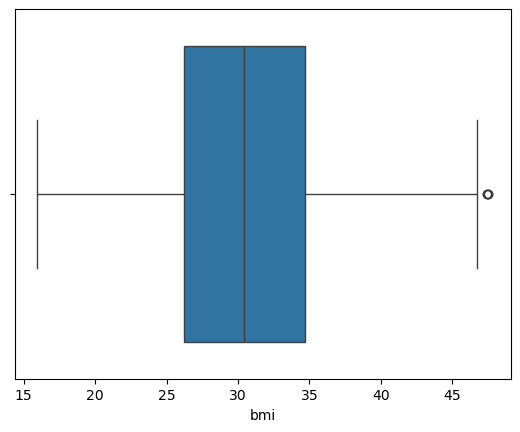

In [204]:
sns.boxplot(df_plt, x="bmi")

Финальная ( наилучшая) модель 

In [205]:
import statsmodels.formula.api as smf

lm = smf.ols("charges~age+bmi+smoker_yes", df_dum).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.747
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     2724.
Date:                Fri, 03 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:58:03   Log-Likelihood:                -28099.
No. Observations:                2772   AIC:                         5.621e+04
Df Residuals:                    2768   BIC:                         5.623e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept          -1.127e+04    649.884    -17.336      0.000   -1.25e+04   -9992.281
smoker_yes[T.True]  2.396e+04    288.633     83.016      0.000    2.34e+04    2.45e+04
age                  258.3508      8.306     31.104      0.000     242.064     274.637
bmi                  311.0192     19.078     16.303      0.000     273.611     348.427
==============================================================================
Omnibus:                      623.426   Durbin-Watson:                   2.082
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1534.959
Skew:                           1.224   Prob(JB):                         0.00
Kurtosis:                       5.702   Cond. No.                         287.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Вывод: после подгрузки данных, были использованы два метода кодирования категориальной информации: Метод One-Hot Encoding (однозначное кодирование) и Метод Label Encoding/OrdinalEncoder (кодирование категорий). Отберем наиболее значимые факторы и рассмотрим построение лучших моделей регрессии (результативный признак - charges) для каждого из методов. Для каждого из методов были построены матрицы парных корреляций пирсона, а также матрицы парных корреляций Пирсона без результативного признака для удобства проверки на мультиколлинеарность. Также были построены диаграммы рассеяния с помощью sns.pairplot, также для анализа зависимостей и определения факторных признаков. При обработке данных методом Метод Label Encoding/OrdinalEncoder наилучшая модель регрессии получилась коэффициентом детерминации 0,747, факторные признаки: age, bmi, smoker, выбранные на основе корреляционных зависимостей и диаграмм рассеяния, мультиколлинеарность между факторными признаками отсутствует. Факторные признаки данного метода имеют наибольшую корреляционную зависимость с результативным. Модели с одним и двумя факторными признаками описывают результативный хуже ( имеют меньший коэффициент детерминации), чем модель со всеми тремя факторами. После очистки факторных признаков модели от выбросов, коэффициент детерминации неизменился, что говорит о незначительности самих выбросов и изначальной точности модели. При обработке данных методом One-Hot Encoding также были построенны несколько моделей регрессии (однофакторные и многофакторные), но уже ожидался наилучший результат у многофакторной модели с тремя факторами, так как данные в общем являются теми же, но из-за различий методов количество самих признаков увеличилось. Для построения моделей были выбраны факторы: age, bmi, smoker_yes. Данные факторы также были проверенны по матрице парных корреляций и диаграммам рассеяния, чтобы удостовериться в правильности выбора. Как и ожидалось наилучшая модель регресси, полученная после проведения метода One-Hot Encoding, также имеет коэффициент детерминации равный 0,747 и три факторных признака age, bmi, smoker_yes. При удалении выбросов из модели коэффициент детерминации также, как и в первом случае остался неизменным. Таким образом можем сказать, что при построении регрессии оба метода предобработки дали одинаковые результаты, что говорит о удобности и качестве обоих методов. Оба метода могут быть использованы. ( Нет лучшего из них). При обработке данных обоими методами, были получены две модели достаточно точно описывающие результативный признак.
